<h1>Imports</h1>

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram,plot_bloch_multivector
from qiskit.circuit.library import DiagonalGate
import numpy as np
from qiskit_ibm_runtime.options_models import simulator
from qiskit_ibm_runtime.fake_provider import FakeFez


<h1>Initialazation Function</h1>

In [2]:
def initialize_s(qc, qubits):
    for q in qubits:
        qc.h(q)
    return qc

<h1>Part 1</h1>


<h1>Diffuser</h1>

In [3]:
def diffuser(nqubits):
    qc = QuantumCircuit(nqubits)

    for qubit in range(nqubits):
        qc.h(qubit)

    for qubit in range(nqubits):
        qc.z(qubit)

    qc.cz(list(range(nqubits - 1)), nqubits - 1)

    for qubit in range(nqubits):
        qc.h(qubit)

    return qc.to_gate()

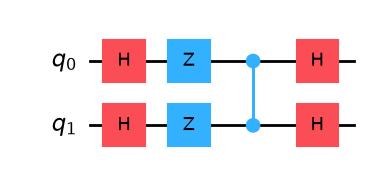

In [4]:
diffuser(2).definition.draw("mpl")

In [8]:
def diffuser(nqubits):
    qc = QuantumCircuit(nqubits)

    # |s> -> |00...0>
    for qubit in range(nqubits):
        qc.h(qubit)

    # |00...0> -> |11...1>
    for qubit in range(nqubits):
        qc.x(qubit)

    # Multi-controlled Z
    qc.h(nqubits - 1)
    qc.mcx(list(range(nqubits - 1)), nqubits - 1)
    qc.h(nqubits - 1)

    # |11...1> -> |00...0>
    for qubit in range(nqubits):
        qc.x(qubit)

    # |00...0> -> |s>
    for qubit in range(nqubits):
        qc.h(qubit)

    U_s = qc.to_gate()
    U_s.name = "$U_s$"

    return U_s

<h1>Gover's Algorithm</h1>

In [6]:

def grover_problem_oracle(n, variant=0, print_solutions=False):
    np.random.seed(variant)

    if n < 3:
        nsolutions = 1
    else:
        nsolutions = np.random.randint(1, np.ceil(2**n/4))
    print("nsolutions =", nsolutions)
    diagonal_elements = [-1]*nsolutions + [1]*((2**n)-nsolutions)
    np.random.shuffle(diagonal_elements)

    oracle_gate = DiagonalGate(diagonal_elements)
    oracle_gate.name = "Oracle\n=%i, var=%i" % (n, variant)

    if print_solutions:
        print("Solutions:")
        for idx, e in enumerate(diagonal_elements):
            if e < 1:
                print("|%s>" % format(idx, "0%ib" % n))


    return oracle_gate


nsolutions = 1
Solutions:
|1101>


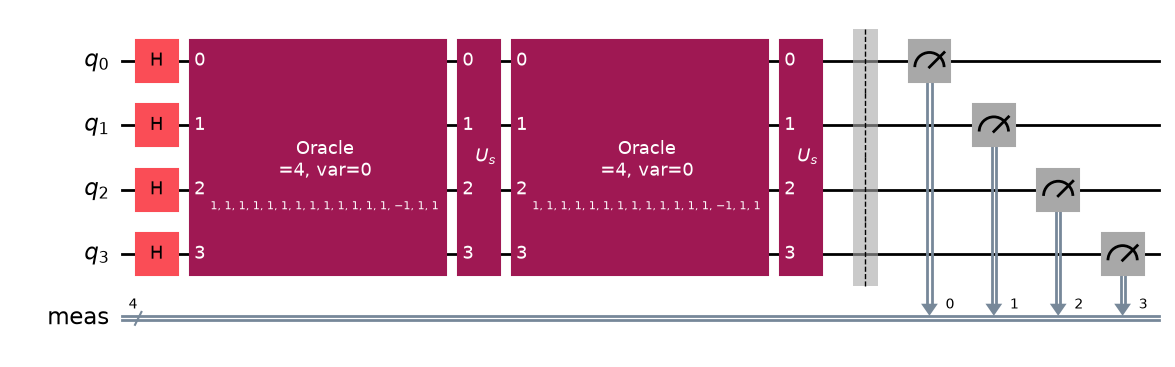

In [7]:
n = 4

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,[0, 1, 2,3])

grover_circuit.append(oracle, [0, 1, 2,3])
grover_circuit.append(diffuser(n), [0, 1, 2,3])

grover_circuit.append(oracle, [0, 1, 2,3])
grover_circuit.append(diffuser(n), [0, 1, 2,3])

grover_circuit.measure_all()

grover_circuit.draw("mpl")

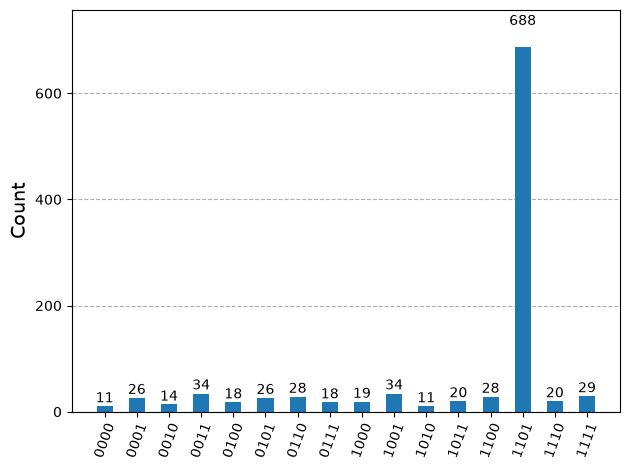

In [8]:
simulator = AerSimulator.from_backend(FakeFez())

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shot=1000)

plot_histogram(job.result().get_counts())

<h1>Two Solution Grover</h1>

In [7]:

def grover_problem_oracle(n, variant=0, print_solutions=False):
    np.random.seed(variant)

    '''if n < 3:
        nsolutions = 2
    else:
        nsolutions = np.random.randint(1, np.ceil(2**n/4))'''

    nsolutions = 2

    diagonal_elements = [-1]*nsolutions + [1]*((2**n)-nsolutions)
    np.random.shuffle(diagonal_elements)

    oracle_gate = DiagonalGate(diagonal_elements)
    oracle_gate.name = "Oracle\n=%i, var=%i" % (n, variant)

    if print_solutions:
        print("Solutions:")
        for idx, e in enumerate(diagonal_elements):
            if e < 1:
                print("|%s>" % format(idx, "0%ib" % n))

    return oracle_gate

Solutions:
|010>
|101>


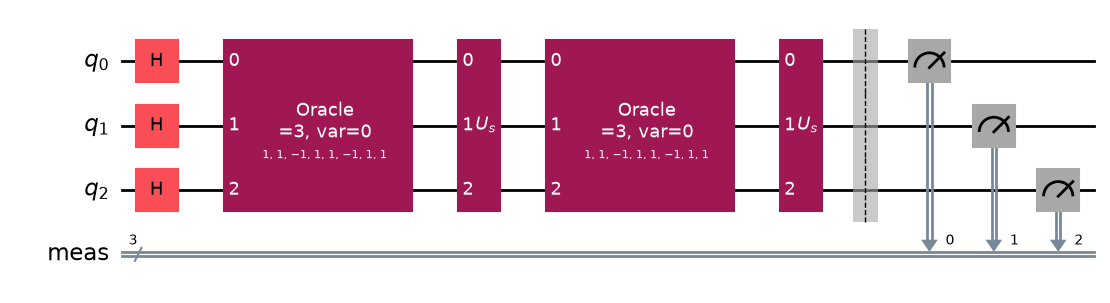

In [10]:
n = 3

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,[0, 1, 2])

grover_circuit.append(oracle, [0, 1, 2])
grover_circuit.append(diffuser(n), [0, 1, 2])

grover_circuit.append(oracle, [0, 1, 2])
grover_circuit.append(diffuser(n), [0, 1, 2])

grover_circuit.measure_all()

grover_circuit.draw("mpl")

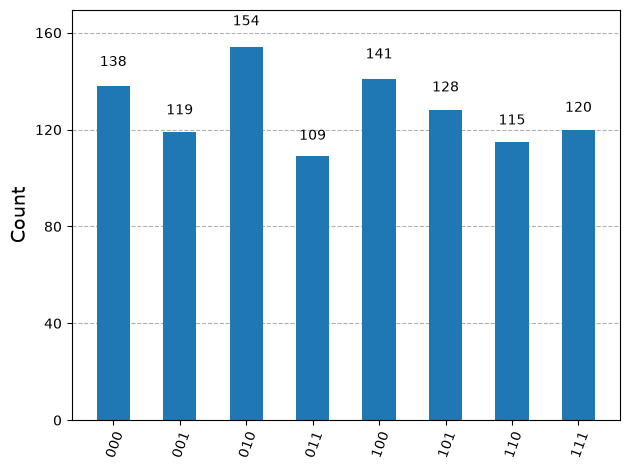

In [11]:
simulator = AerSimulator.from_backend(FakeFez())

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shot=1000)

plot_histogram(job.result().get_counts())

Solutions:
|10>
|11>


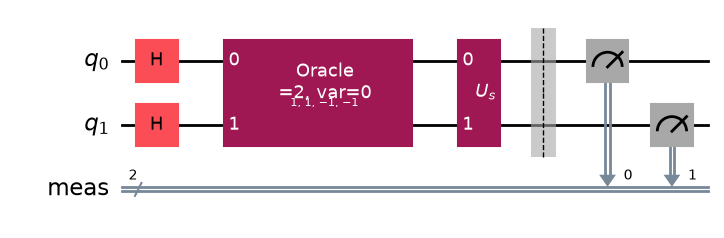

In [49]:
n = 2
iterations = 1

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,range(n))

for i in range(iterations):
    grover_circuit.append(oracle, range(n))
    grover_circuit.append(diffuser(n), range(n))

grover_circuit.measure_all()

grover_circuit.draw("mpl")

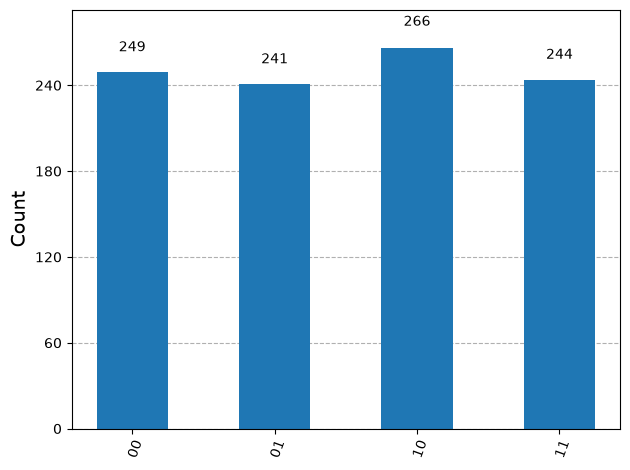

In [50]:
simulator = AerSimulator.from_backend(FakeFez())

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shots=1000)

plot_histogram(job.result().get_counts())

Solutions:
|010>
|101>


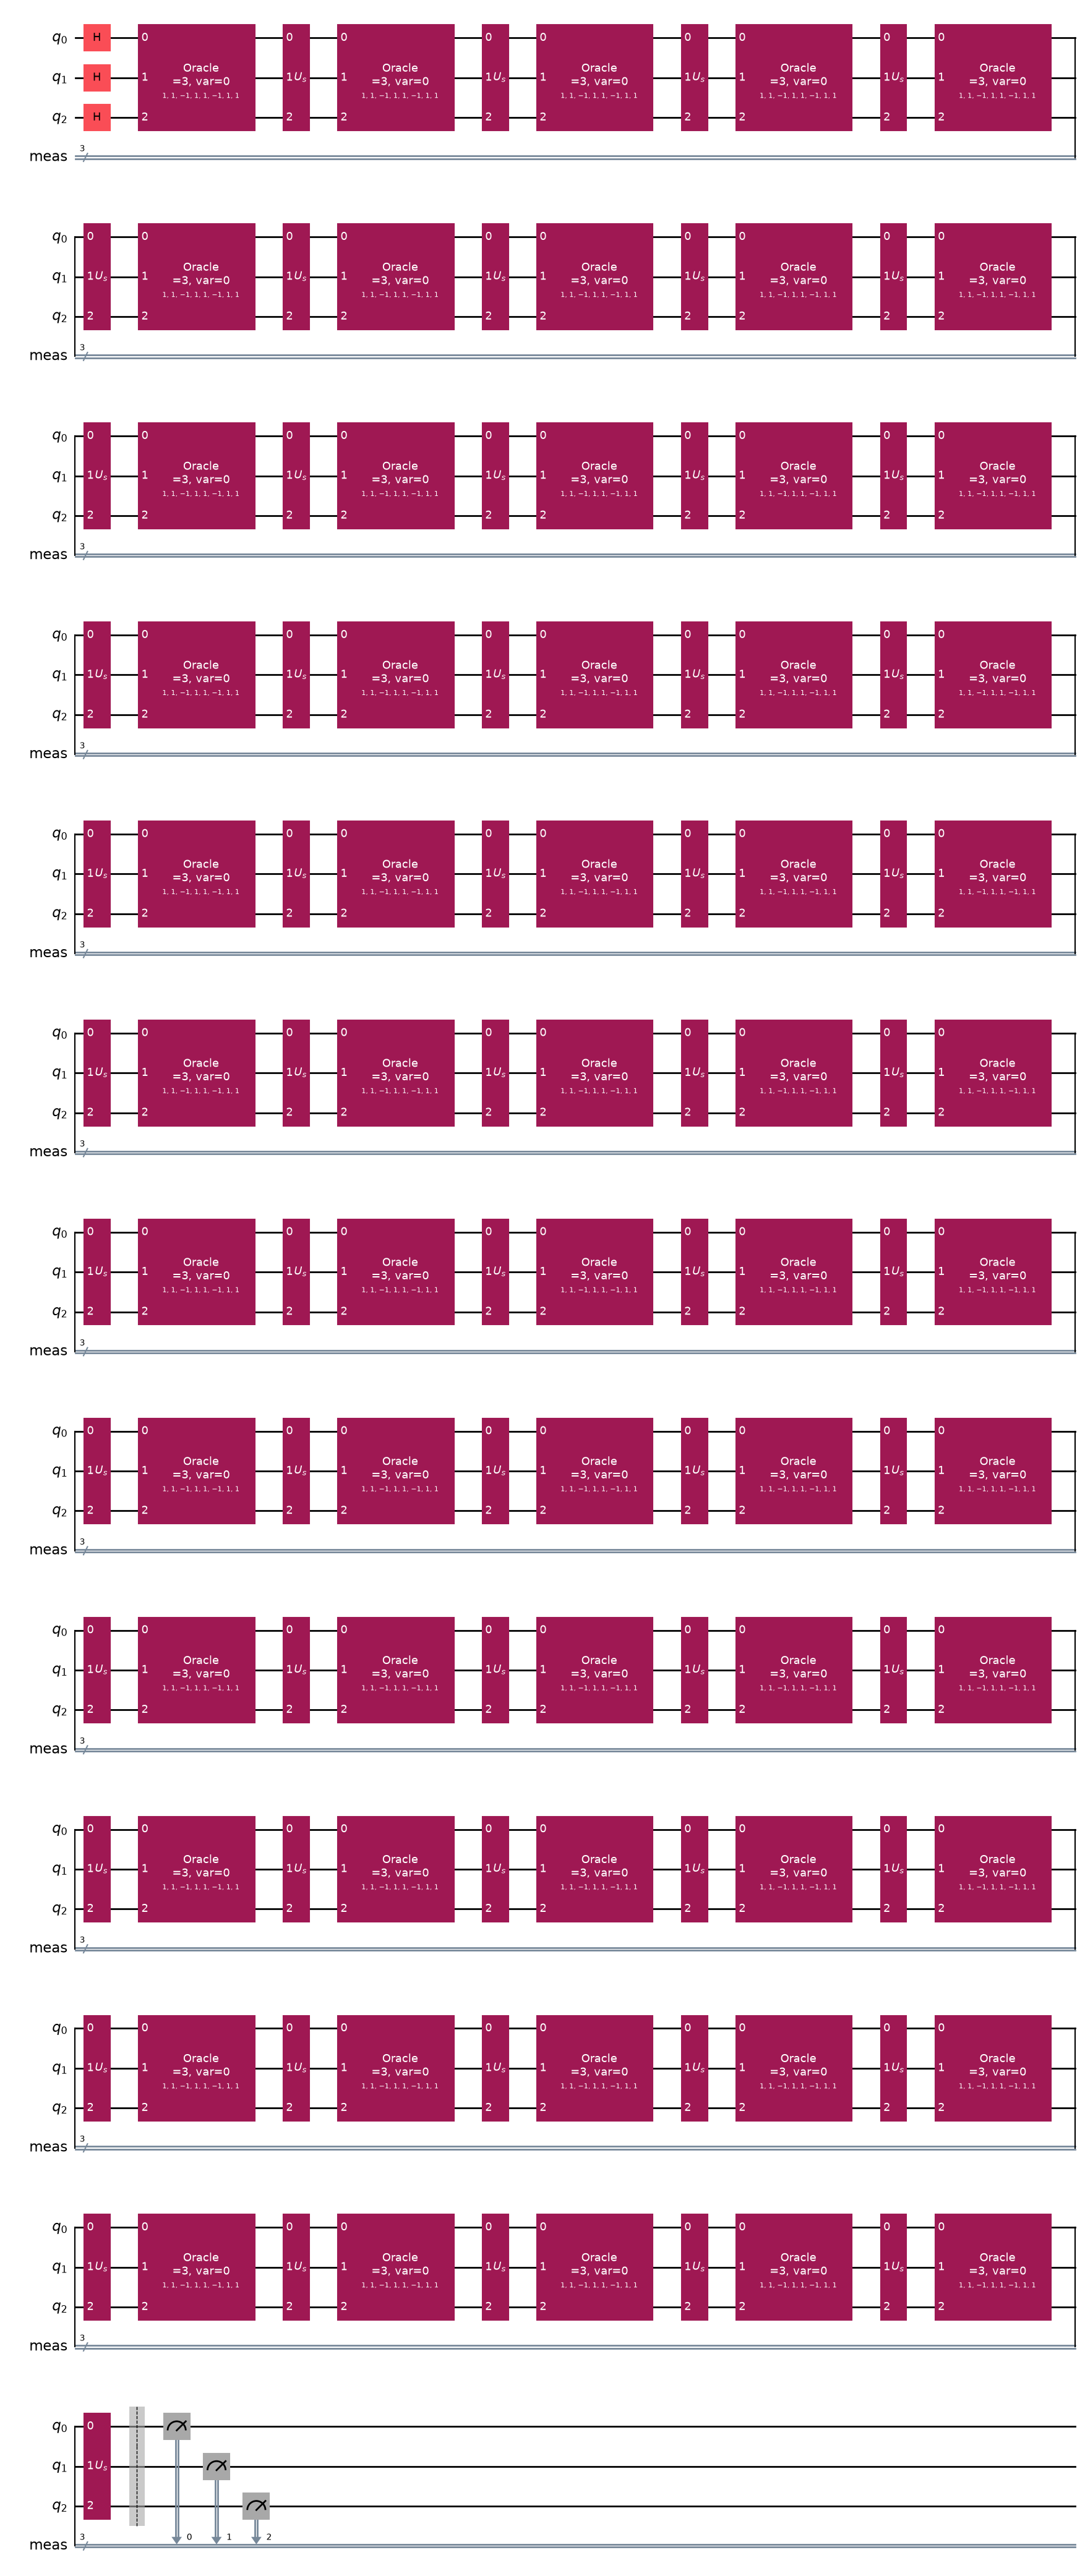

In [24]:
n = 3
#iterations = 45
iterations = 60

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,range(n))

for i in range(iterations):
    grover_circuit.append(oracle, range(n))
    grover_circuit.append(diffuser(n), range(n))

grover_circuit.measure_all()

grover_circuit.draw("mpl")

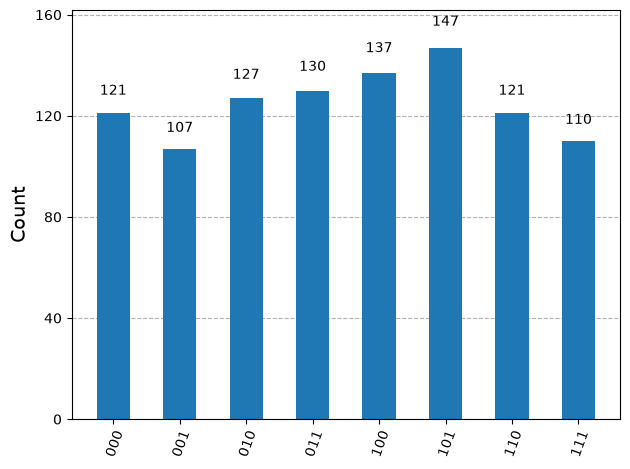

In [25]:
simulator = AerSimulator.from_backend(FakeFez())

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shots=1000)

plot_histogram(job.result().get_counts())

Solutions:
|0000>
|1101>


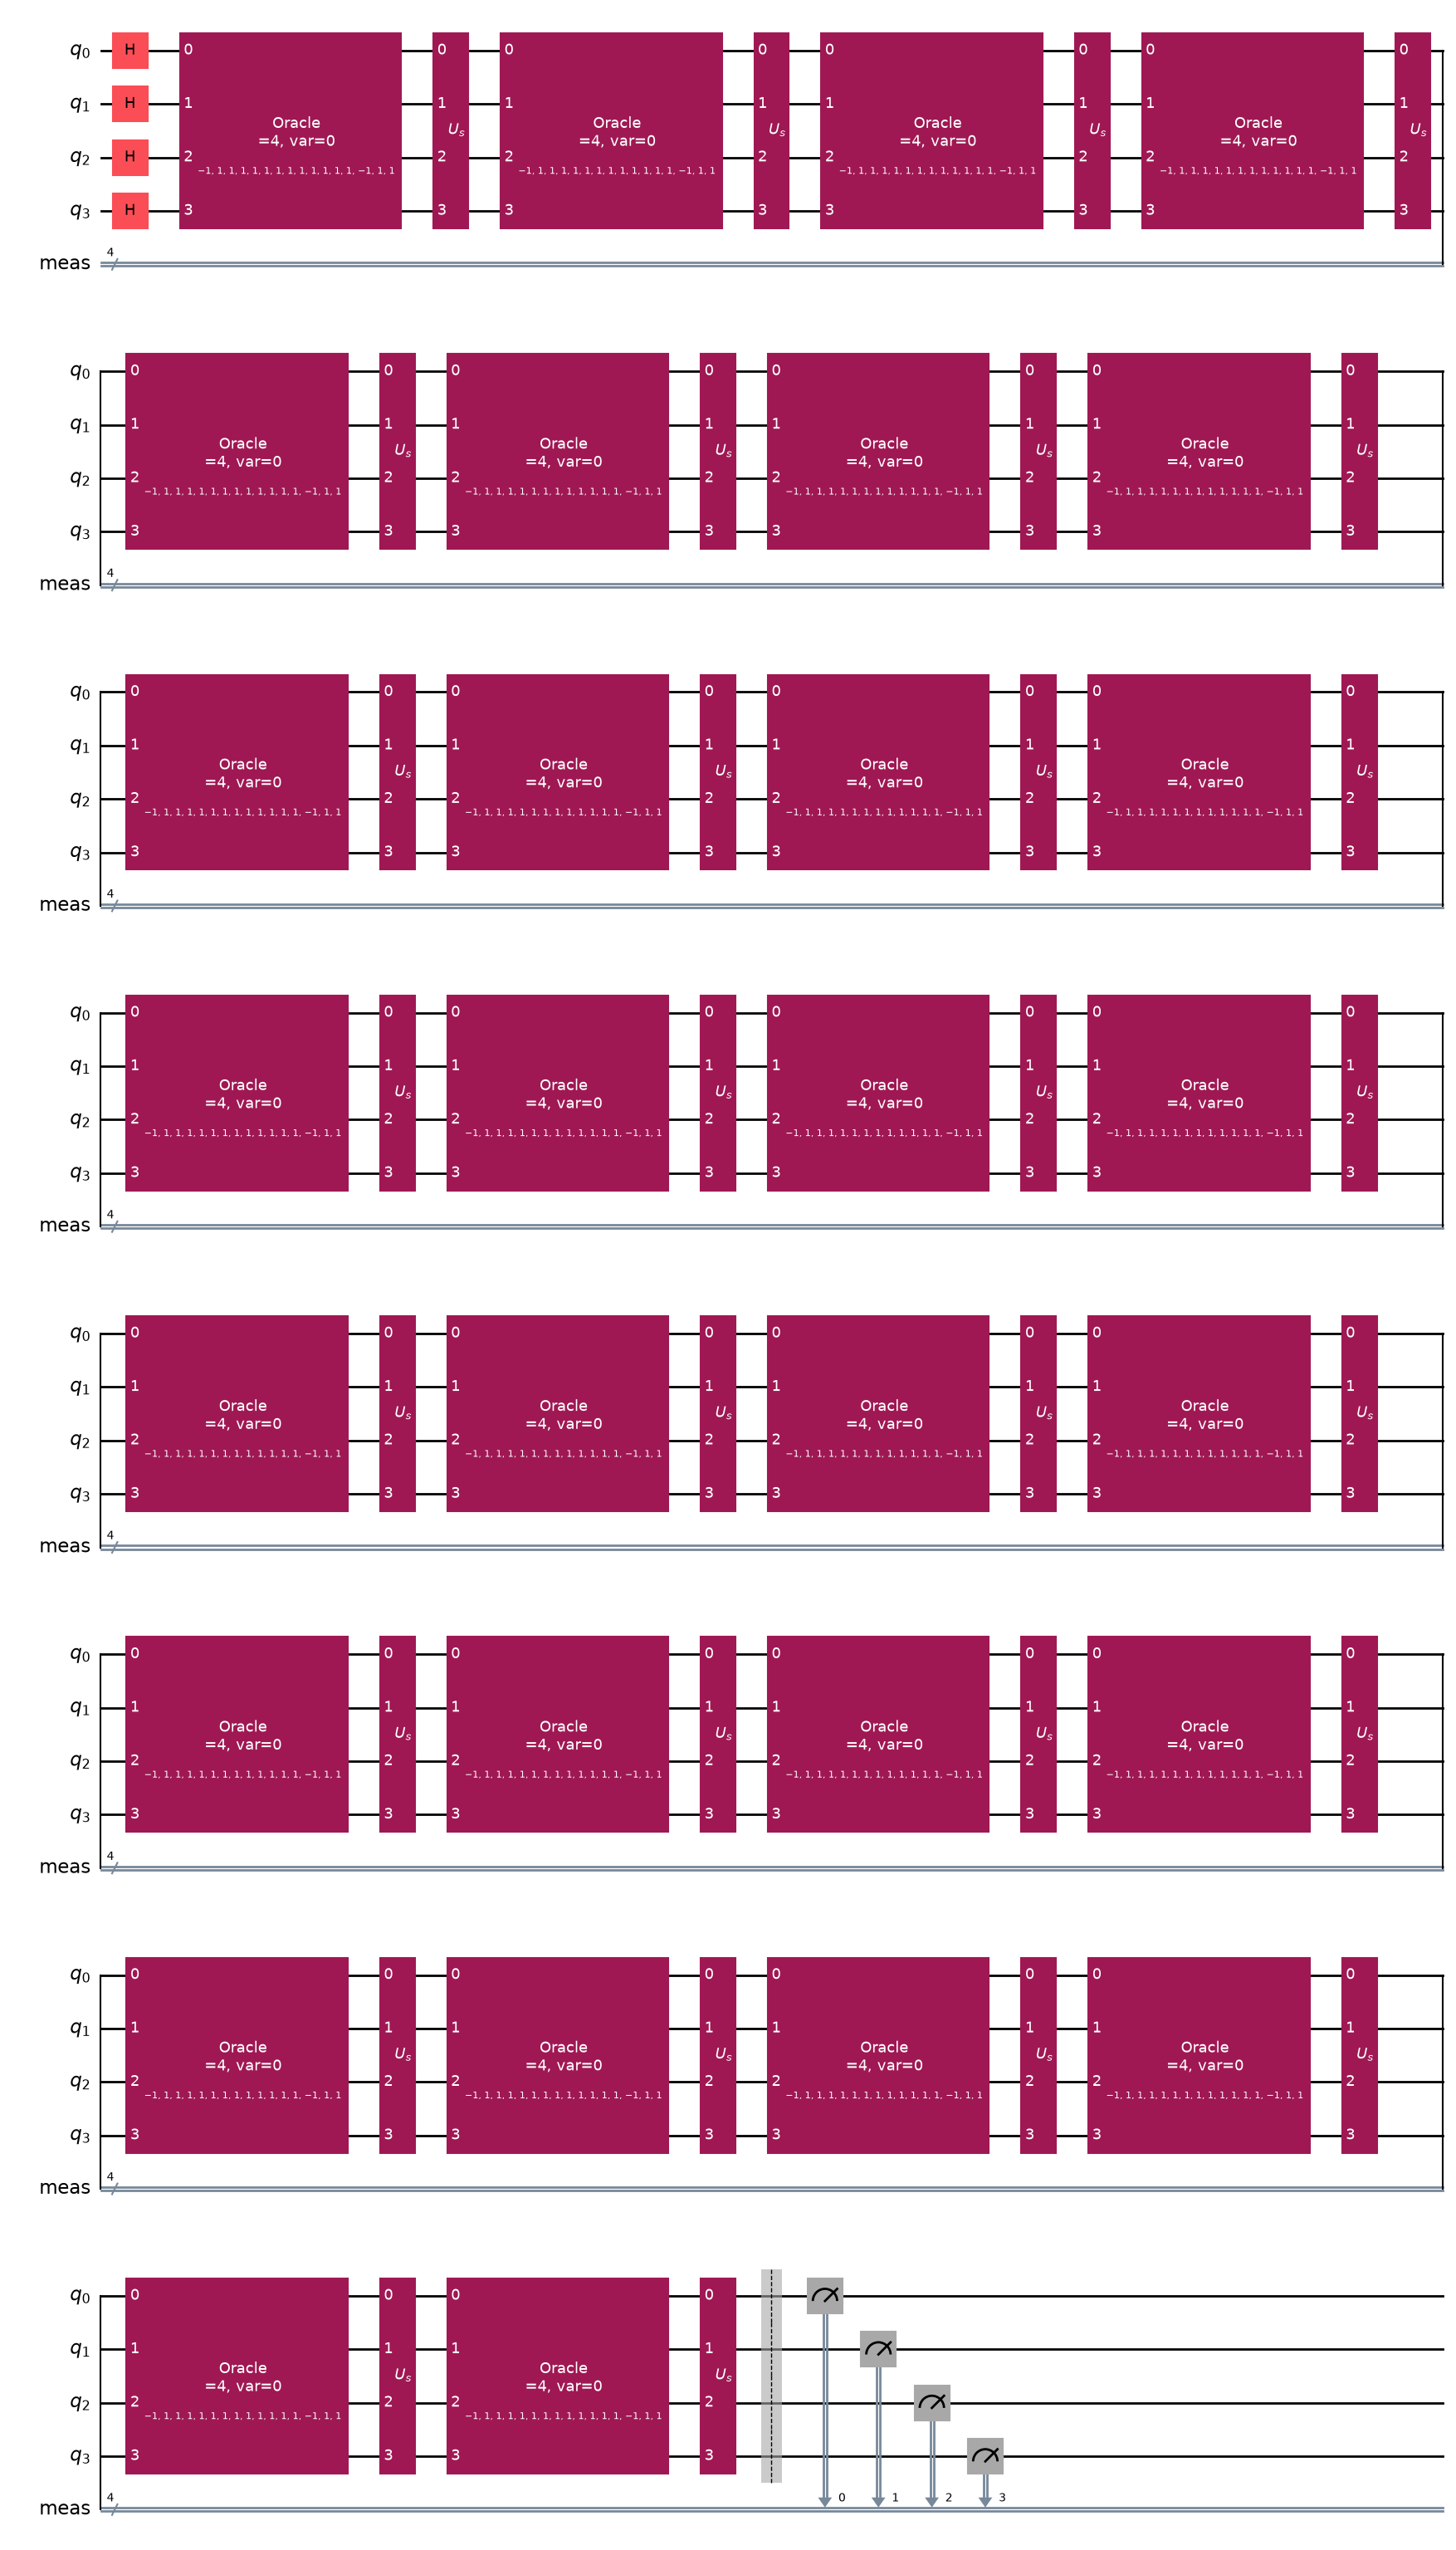

In [33]:
n = 4
#iterations = 45
iterations = 30

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,range(n))

for i in range(iterations):
    grover_circuit.append(oracle, range(n))
    grover_circuit.append(diffuser(n), range(n))

grover_circuit.measure_all()

grover_circuit.draw("mpl")

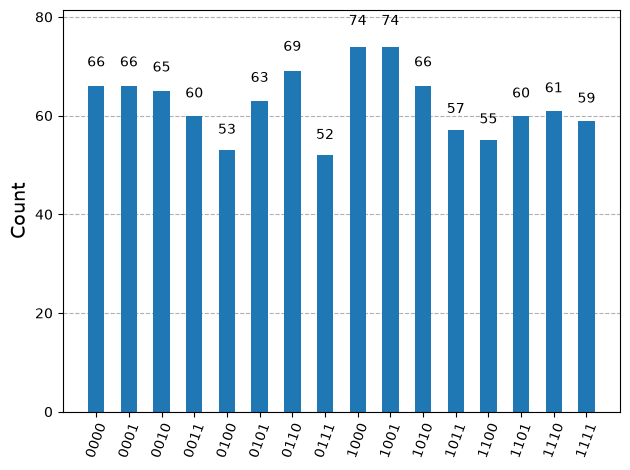

In [34]:
simulator = AerSimulator.from_backend(FakeFez())

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shots=1000)

plot_histogram(job.result().get_counts())

Solutions:
|10001>
|11100>


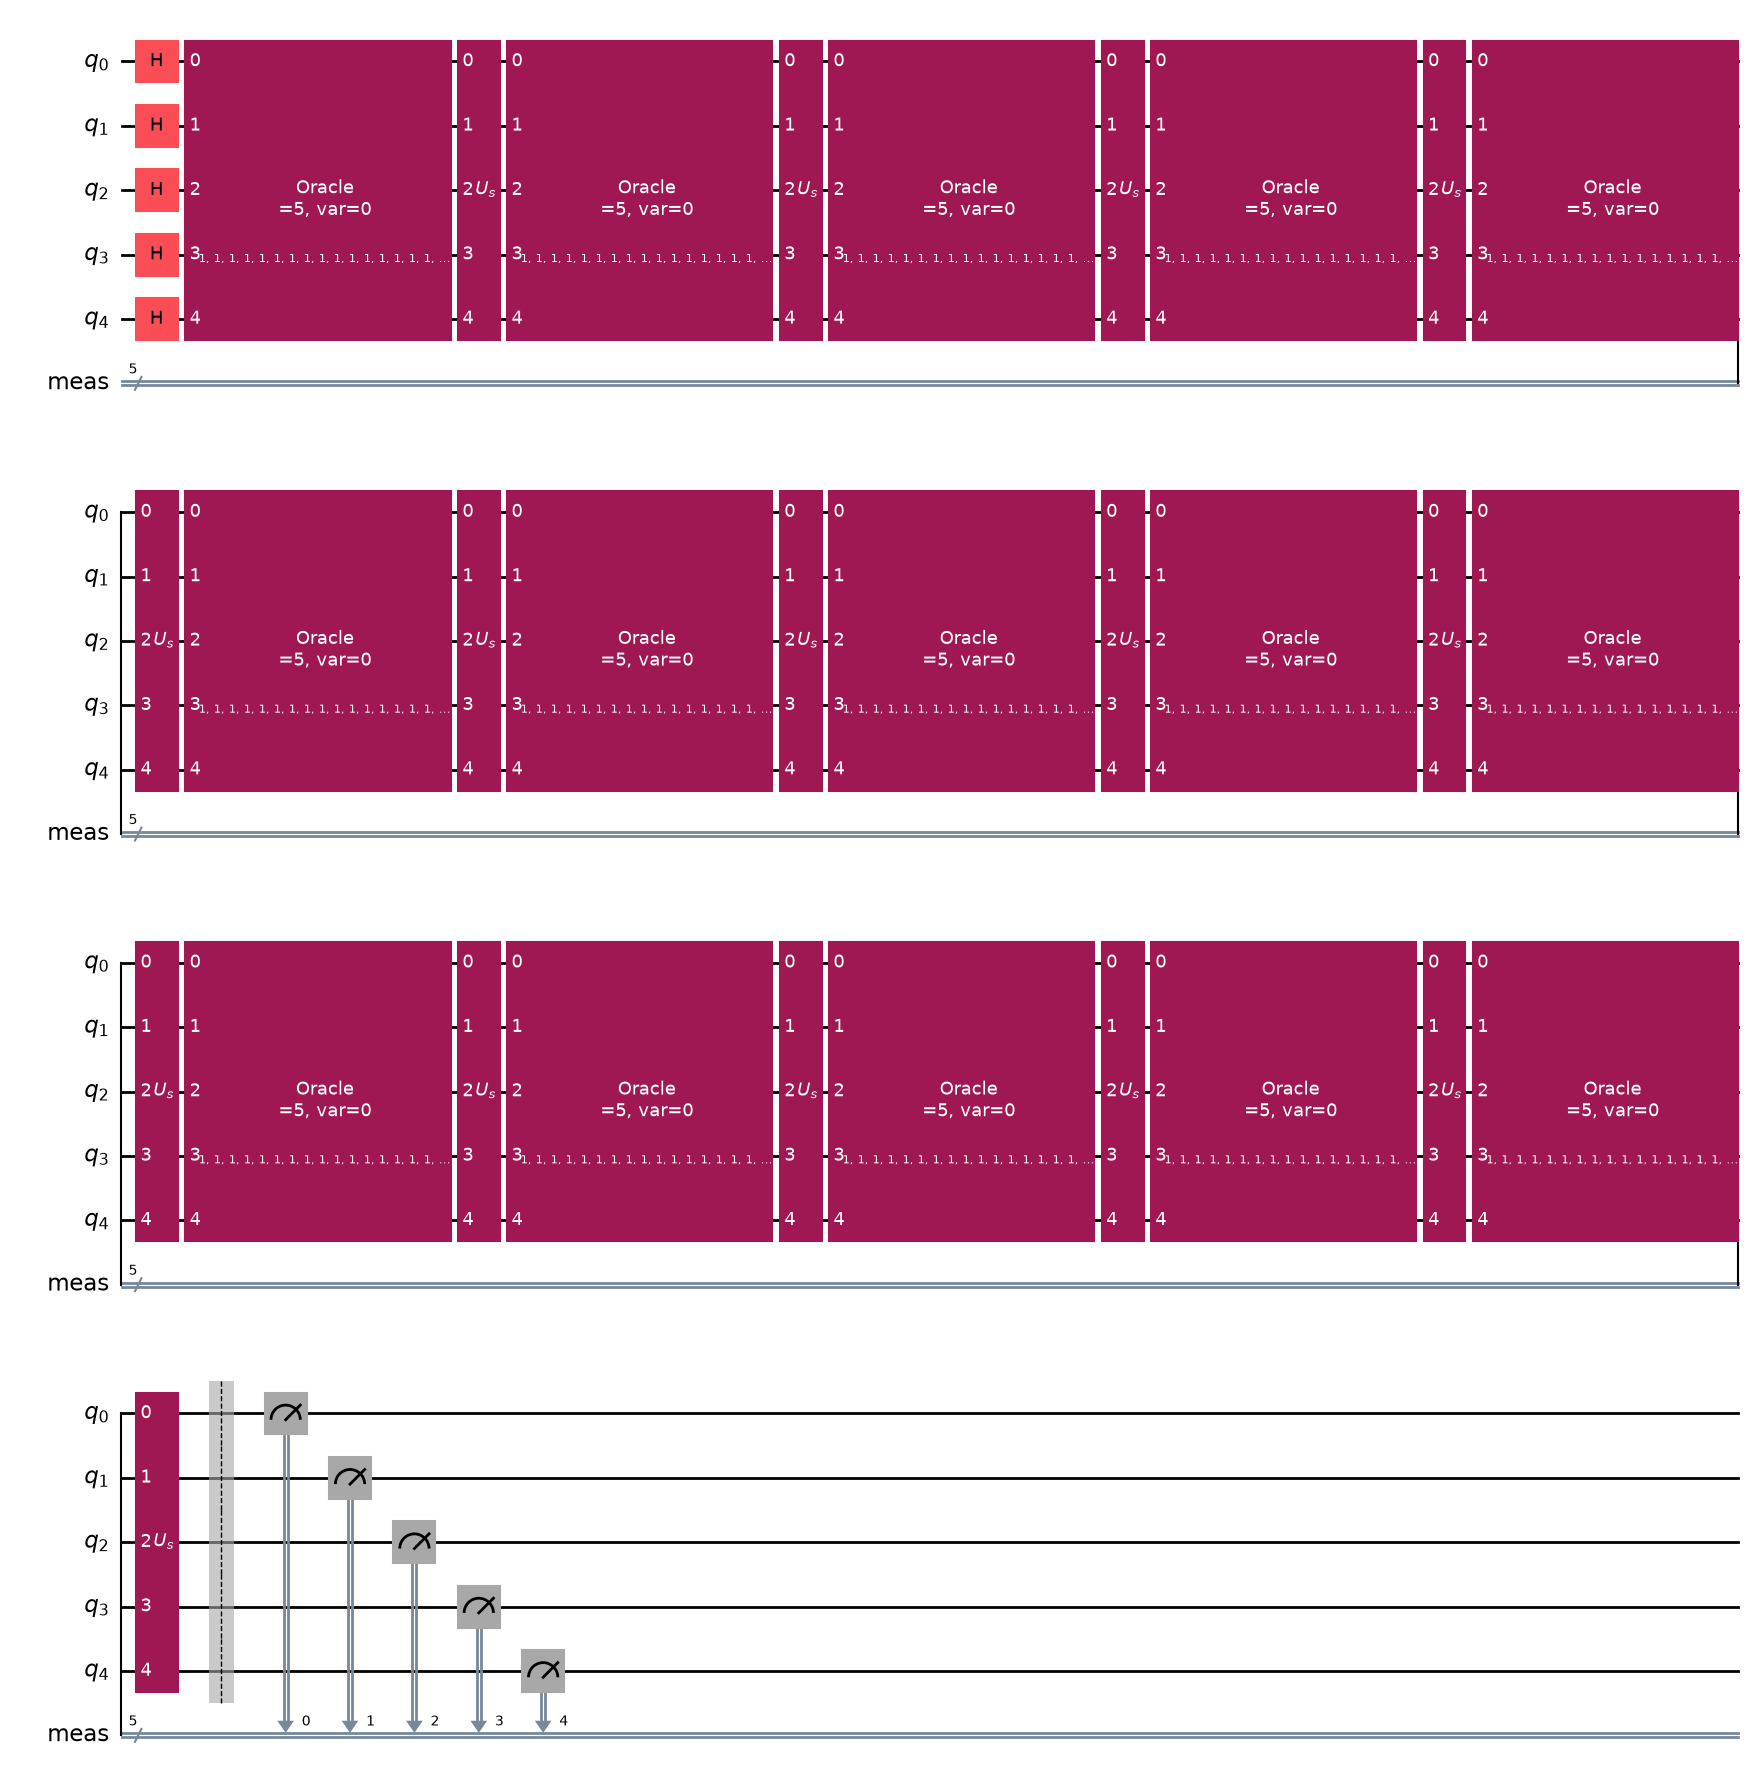

In [47]:
n = 5
#iterations = 45
iterations = 15

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,range(n))

for i in range(iterations):
    grover_circuit.append(oracle, range(n))
    grover_circuit.append(diffuser(n), range(n))

grover_circuit.measure_all()

grover_circuit.draw("mpl")

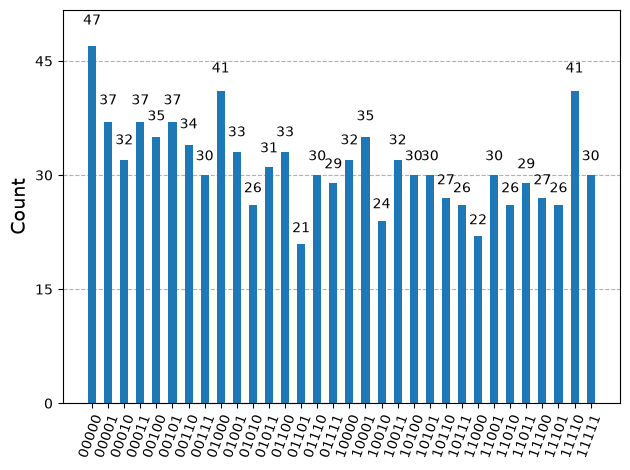

In [48]:
simulator = AerSimulator.from_backend(FakeFez())

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shots=1000)

plot_histogram(job.result().get_counts())

<h1>Two slution reral quantum computer verification</h1>

In [3]:
from qiskit_ibm_runtime import QiskitRuntimeService
import os
from dotenv import load_dotenv
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
load_dotenv(".env", override=True)

QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token=os.getenv("API"),
    instance=os.getenv("CRN"),
    set_as_default=True
)

service = QiskitRuntimeService()

print(service.backends())

[<IBMBackend('ibm_fez')>, <IBMBackend('ibm_kingston')>, <IBMBackend('ibm_marrakesh')>]


In [4]:
backend = service.backend("ibm_fez")

print(backend.name)
print(backend.status())

ibm_fez


<h2>Making the code ready to run on a quantum computer</h2>

In [5]:
def grover_quantum(n, iterations):
    oracle = grover_problem_oracle(n, variant=0, print_solutions=True)

    grover_circuit = QuantumCircuit(n)

    grover_circuit = initialize_s(grover_circuit, range(n))

    for i in range(iterations):
        grover_circuit.append(oracle, range(n))
        grover_circuit.append(diffuser(n), range(n))

    grover_circuit.measure_all()

    return grover_circuit


Solutions:
|10>
|11>


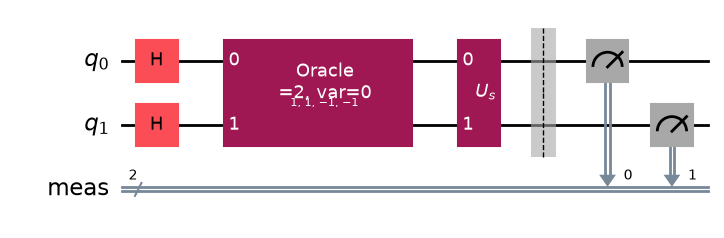

In [9]:
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

pm = generate_preset_pass_manager(backend=backend,optimization_level=1)

quantum = grover_quantum(2, 1)

Qcircuit = pm.run(quantum)

quantum.draw("mpl")

In [58]:
sampler = Sampler(mode=backend)

job = sampler.run([Qcircuit], shots=1000)

print("Job ID:", job.job_id())

C:\Users\morta\AppData\Local\Temp\ipykernel_33028\1176520652.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Job ID: dbbu0rvi0auc73dtoi80


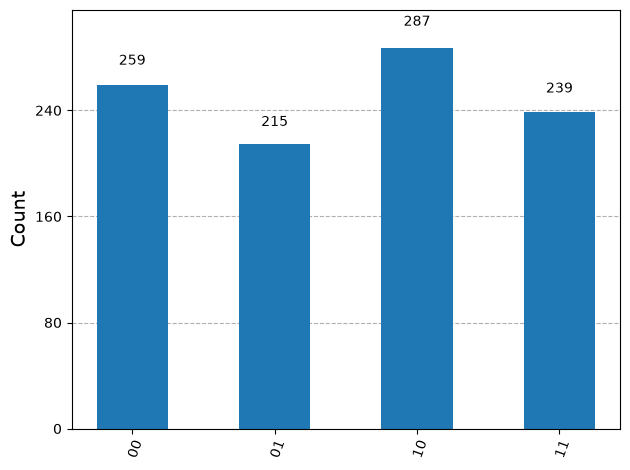

In [59]:
result = job.result()

counts = result[0].data.meas.get_counts()

plot_histogram(counts)

In [60]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

Solutions:
|010>
|101>
Job ID: dbbu3j9gv2cc73e95dhg


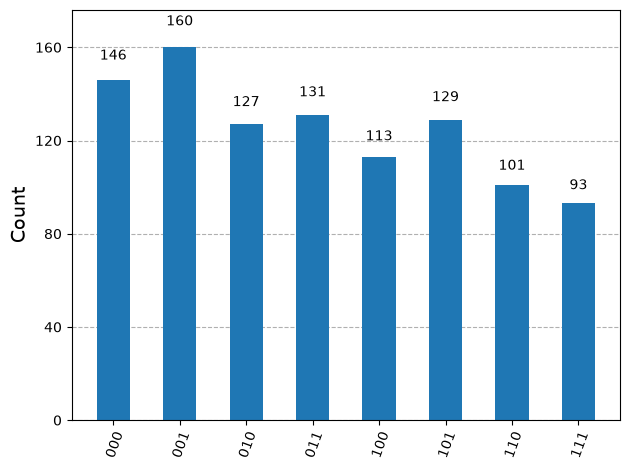

In [61]:
quantum = grover_quantum(3, 60)

Qcircuit = pm.run(quantum)

quantum.draw("mpl")

sampler = Sampler(mode=backend)

job = sampler.run([Qcircuit], shots=1000)

print("Job ID:", job.job_id())

result = job.result()

counts = result[0].data.meas.get_counts()

plot_histogram(counts)

Solutions:
|0000>
|1101>
Job ID: dbbu6goc77vs73853ohg


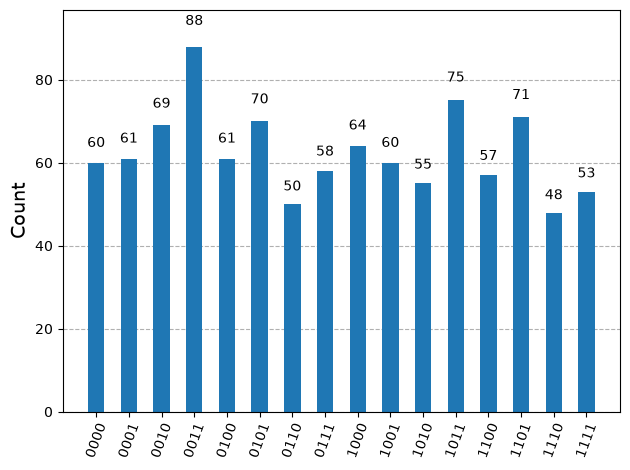

In [62]:
quantum = grover_quantum(4, 30)

Qcircuit = pm.run(quantum)

quantum.draw("mpl")

sampler = Sampler(mode=backend)

job = sampler.run([Qcircuit], shots=1000)

print("Job ID:", job.job_id())

result = job.result()

counts = result[0].data.meas.get_counts()

plot_histogram(counts)

In [ ]:
quantum = grover_quantum(5, 15)

Qcircuit = pm.run(quantum)

quantum.draw("mpl")

sampler = Sampler(mode=backend)

job = sampler.run([Qcircuit], shots=1000)

print("Job ID:", job.job_id())

result = job.result()

counts = result[0].data.meas.get_counts()

plot_histogram(counts)

<h1>3 Slution oracel</h1>

In [10]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (24, 8),
    "figure.dpi": 120,
    "font.size": 12,
    "xtick.labelsize": 8,
    "ytick.labelsize": 11,
    "xtick.major.size": 5,
    "figure.autolayout": True
})

In [11]:

def grover_problem_oracle(n, variant=0, print_solutions=False):
    np.random.seed(variant)

    '''if n < 3:
        nsolutions = 2
    else:
        nsolutions = np.random.randint(1, np.ceil(2**n/4))'''

    nsolutions = 3

    diagonal_elements = [-1]*nsolutions + [1]*((2**n)-nsolutions)
    np.random.shuffle(diagonal_elements)

    oracle_gate = DiagonalGate(diagonal_elements)
    oracle_gate.name = "Oracle\n=%i, var=%i" % (n, variant)

    if print_solutions:
        print("Solutions:")
        for idx, e in enumerate(diagonal_elements):
            if e < 1:
                print("|%s>" % format(idx, "0%ib" % n))

    return oracle_gate

Solutions:
|001>
|010>
|101>


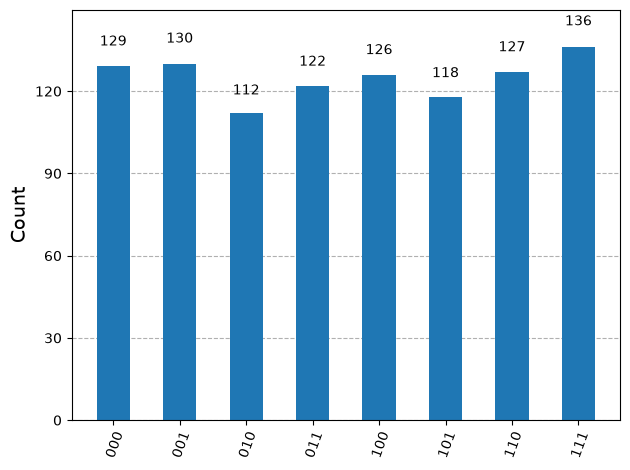

In [12]:
n = 3
iterations = 35

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,range(n))

for i in range(iterations):
    grover_circuit.append(oracle, range(n))
    grover_circuit.append(diffuser(n), range(n))

grover_circuit.measure_all()

grover_circuit.draw("mpl")

simulator = AerSimulator.from_backend(FakeFez())

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shots=1000)

plot_histogram(job.result().get_counts())

Solutions:
|0000>
|0110>
|1101>


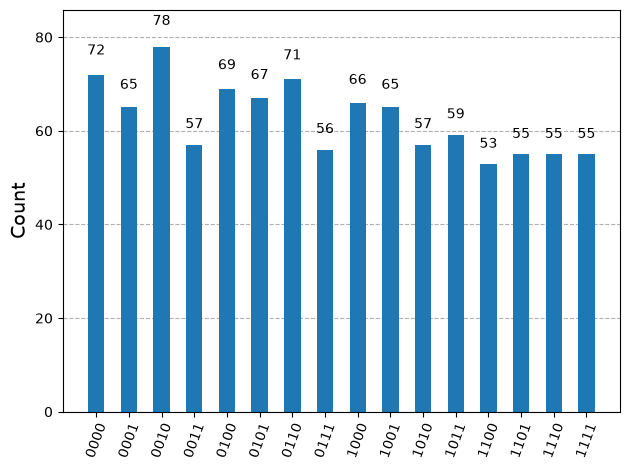

In [15]:
n = 4
iterations = 20

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,range(n))

for i in range(iterations):
    grover_circuit.append(oracle, range(n))
    grover_circuit.append(diffuser(n), range(n))

grover_circuit.measure_all()

grover_circuit.draw("mpl")

simulator = AerSimulator.from_backend(FakeFez())

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shots=1000)

plot_histogram(job.result().get_counts())

Solutions:
|00011>
|10001>
|11100>


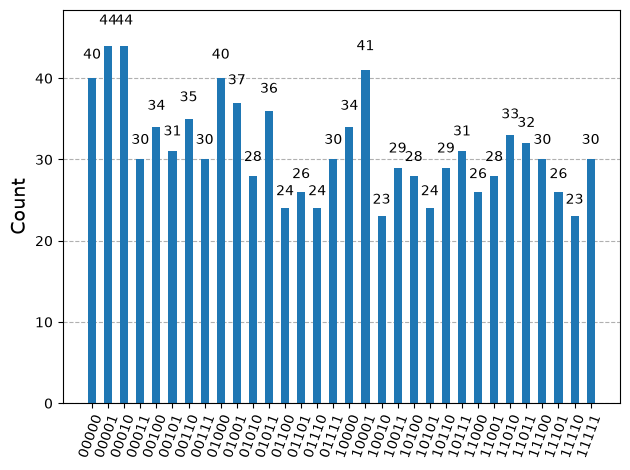

In [19]:
n = 5
iterations = 10

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,range(n))

for i in range(iterations):
    grover_circuit.append(oracle, range(n))
    grover_circuit.append(diffuser(n), range(n))

grover_circuit.measure_all()

grover_circuit.draw("mpl")

simulator = AerSimulator.from_backend(FakeFez())

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shots=1000)

plot_histogram(job.result().get_counts())

Solutions:
|001011>
|101110>
|111100>


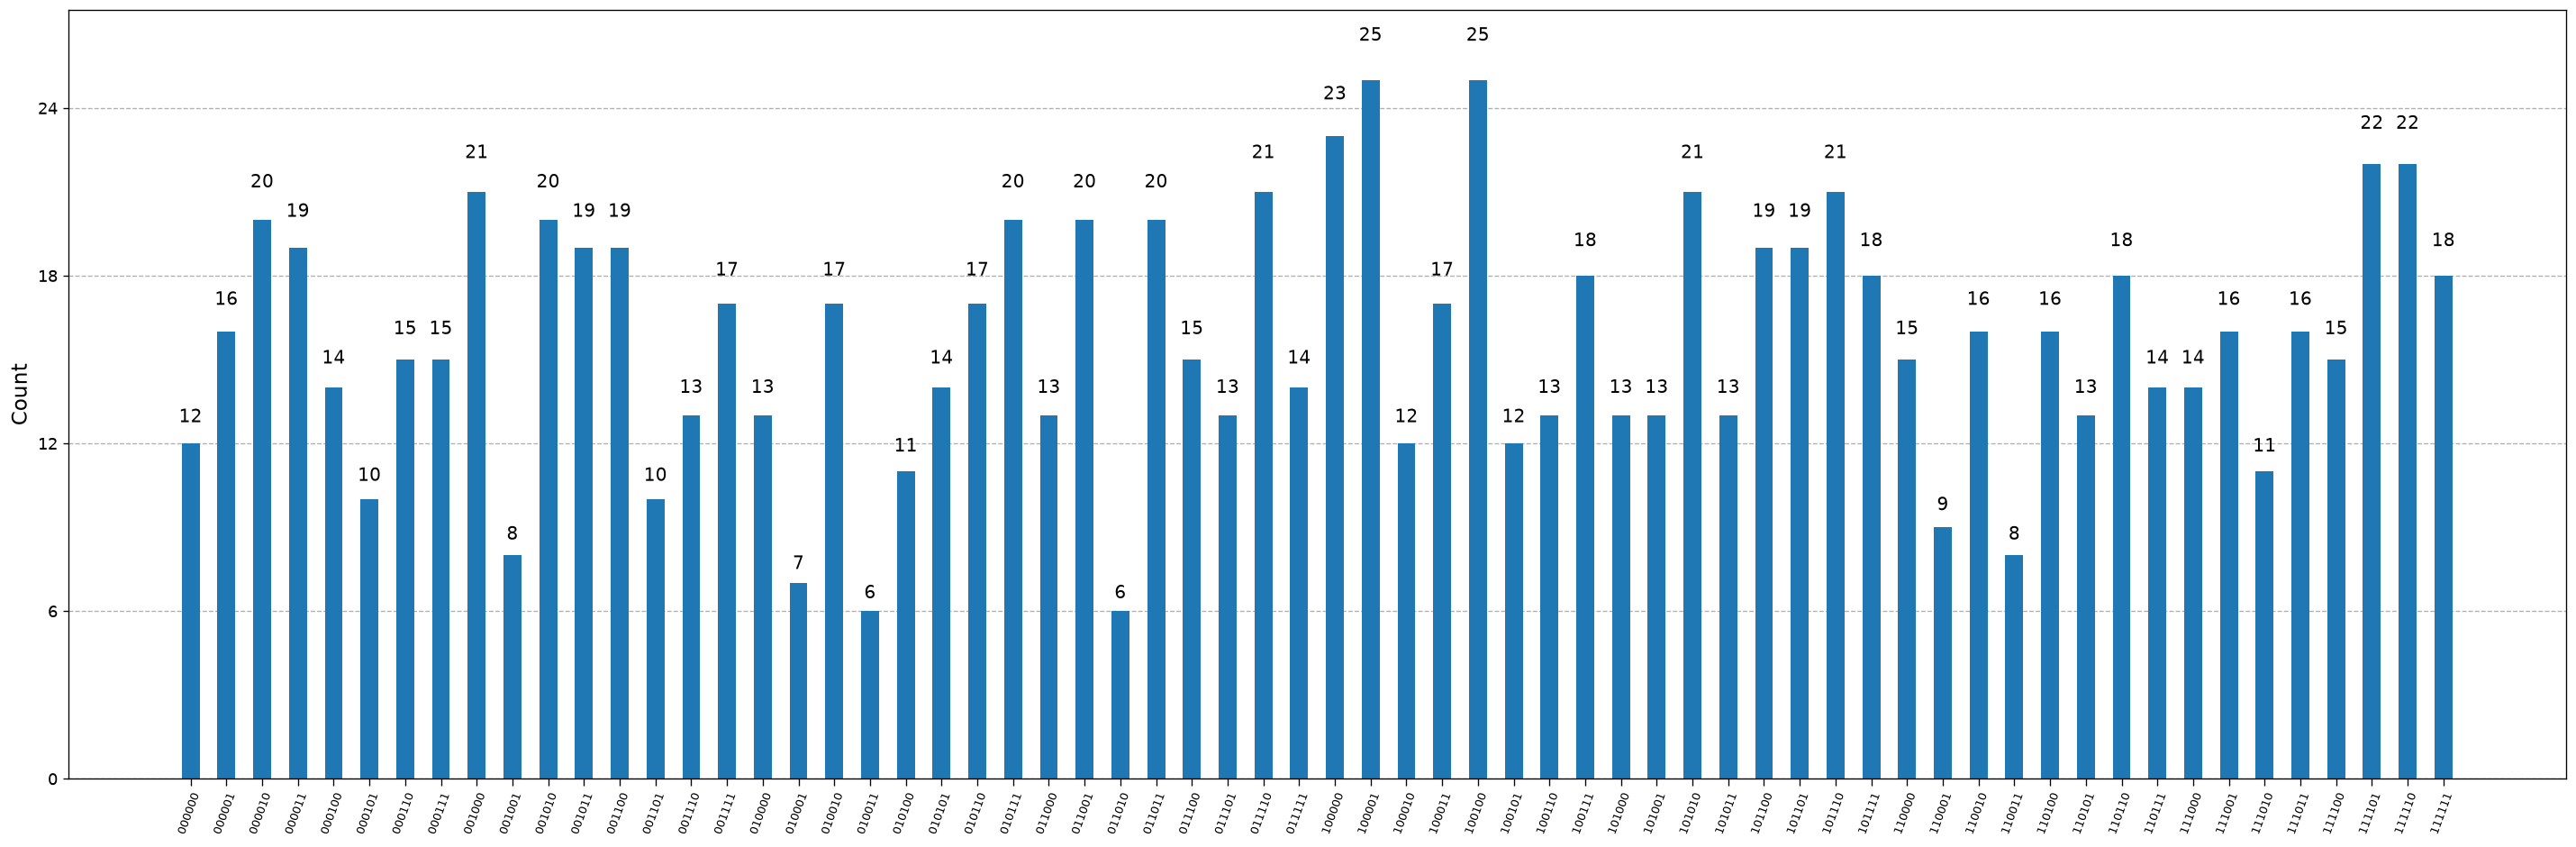

In [22]:
n = 6
iterations = 5

oracle = grover_problem_oracle(n,variant=0,print_solutions=True)

grover_circuit = QuantumCircuit(n)

grover_circuit = initialize_s(grover_circuit,range(n))

for i in range(iterations):
    grover_circuit.append(oracle, range(n))
    grover_circuit.append(diffuser(n), range(n))

grover_circuit.measure_all()

grover_circuit.draw("mpl")

simulator = AerSimulator.from_backend(FakeFez())

qcc = transpile(grover_circuit, simulator)

job = simulator.run(qcc,shots=1000)

plot_histogram(job.result().get_counts())

In [14]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

3 qbits 35 iterations
Solutions:
|001>
|010>
|101>
Job ID: dbdo3ooc77vs73eu9v8g


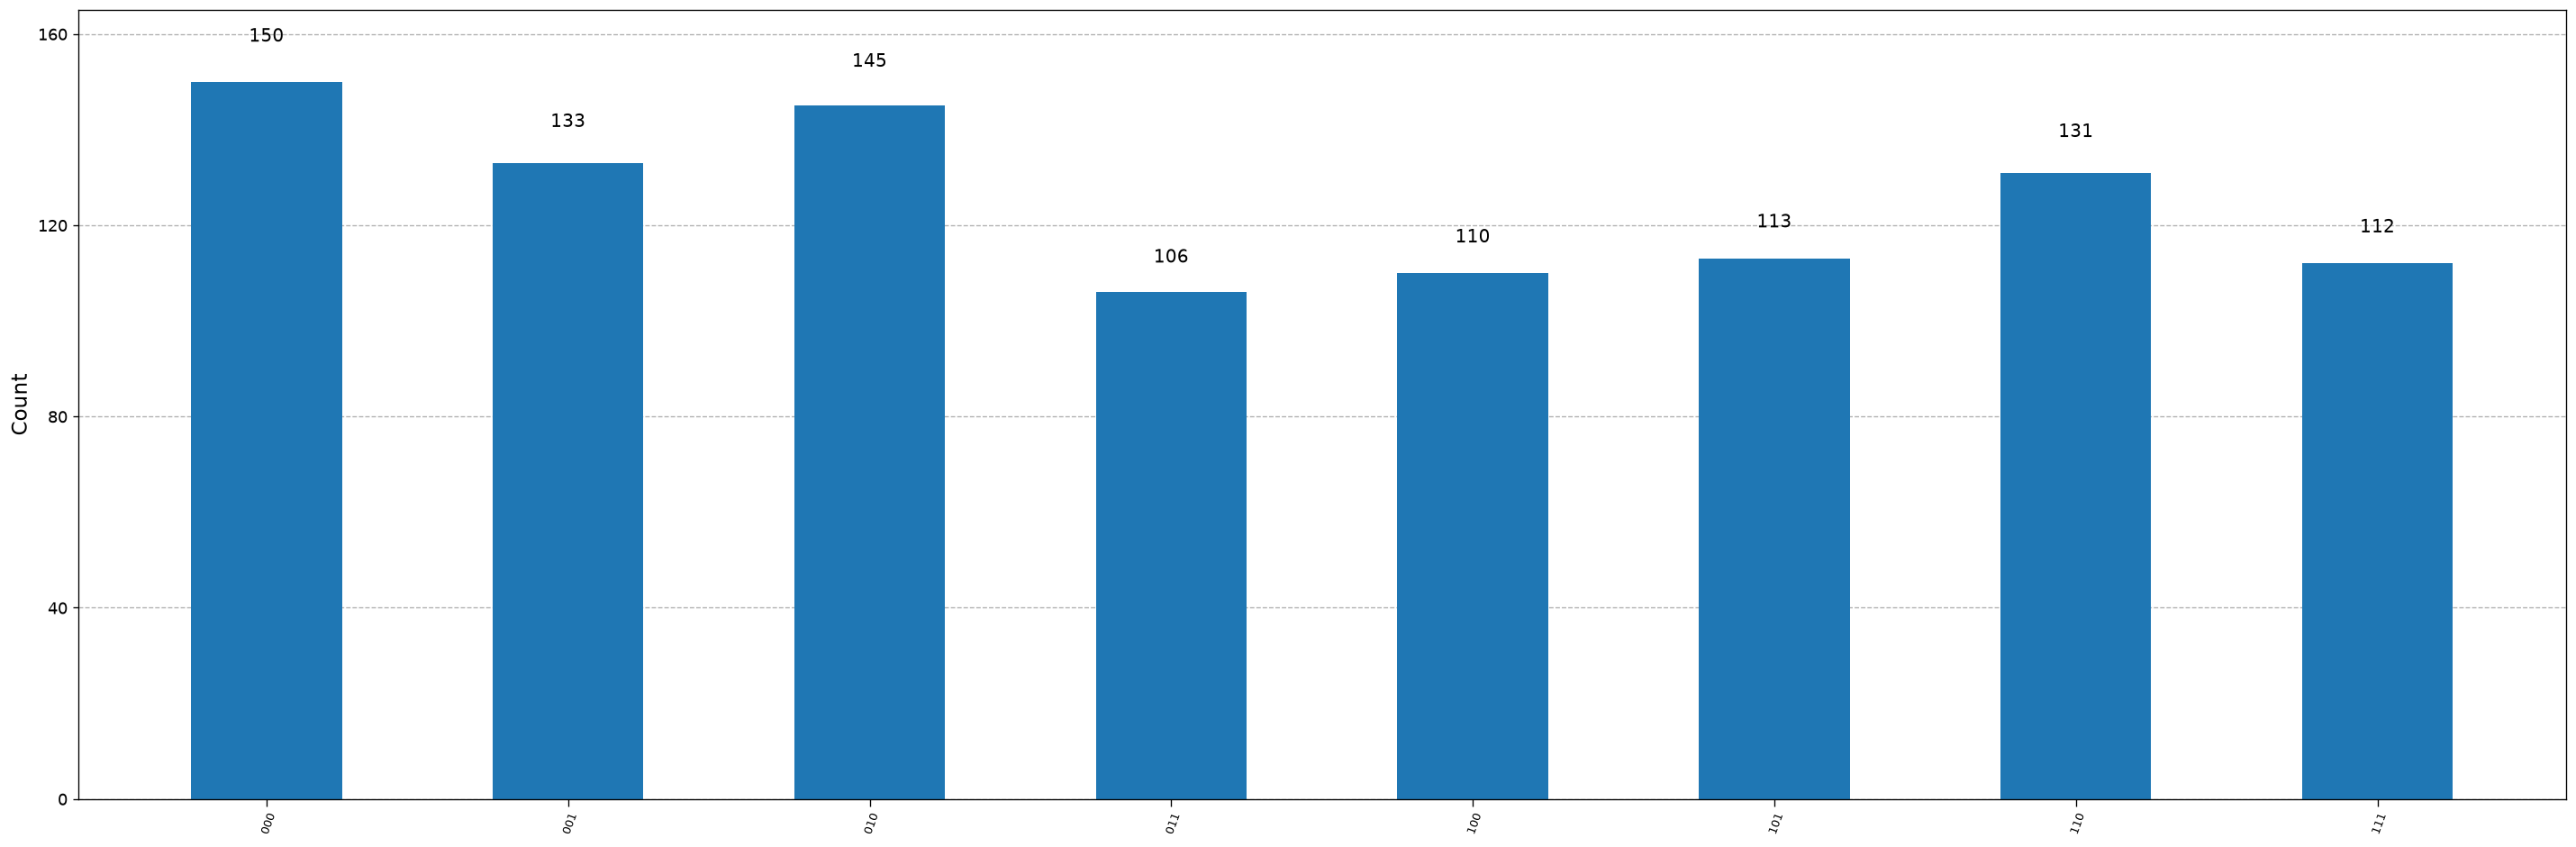

In [15]:
print ("3 qbits 35 iterations")
quantum = grover_quantum(3, 35)

Qcircuit = pm.run(quantum)

quantum.draw("mpl")

sampler = Sampler(mode=backend)

job = sampler.run([Qcircuit], shots=1000)

print("Job ID:", job.job_id())

result = job.result()

counts = result[0].data.meas.get_counts()

plot_histogram(counts)



4 qbits 20 iterations
Solutions:
|0000>
|0110>
|1101>
Job ID: dbdo3rni0auc73crgbn0


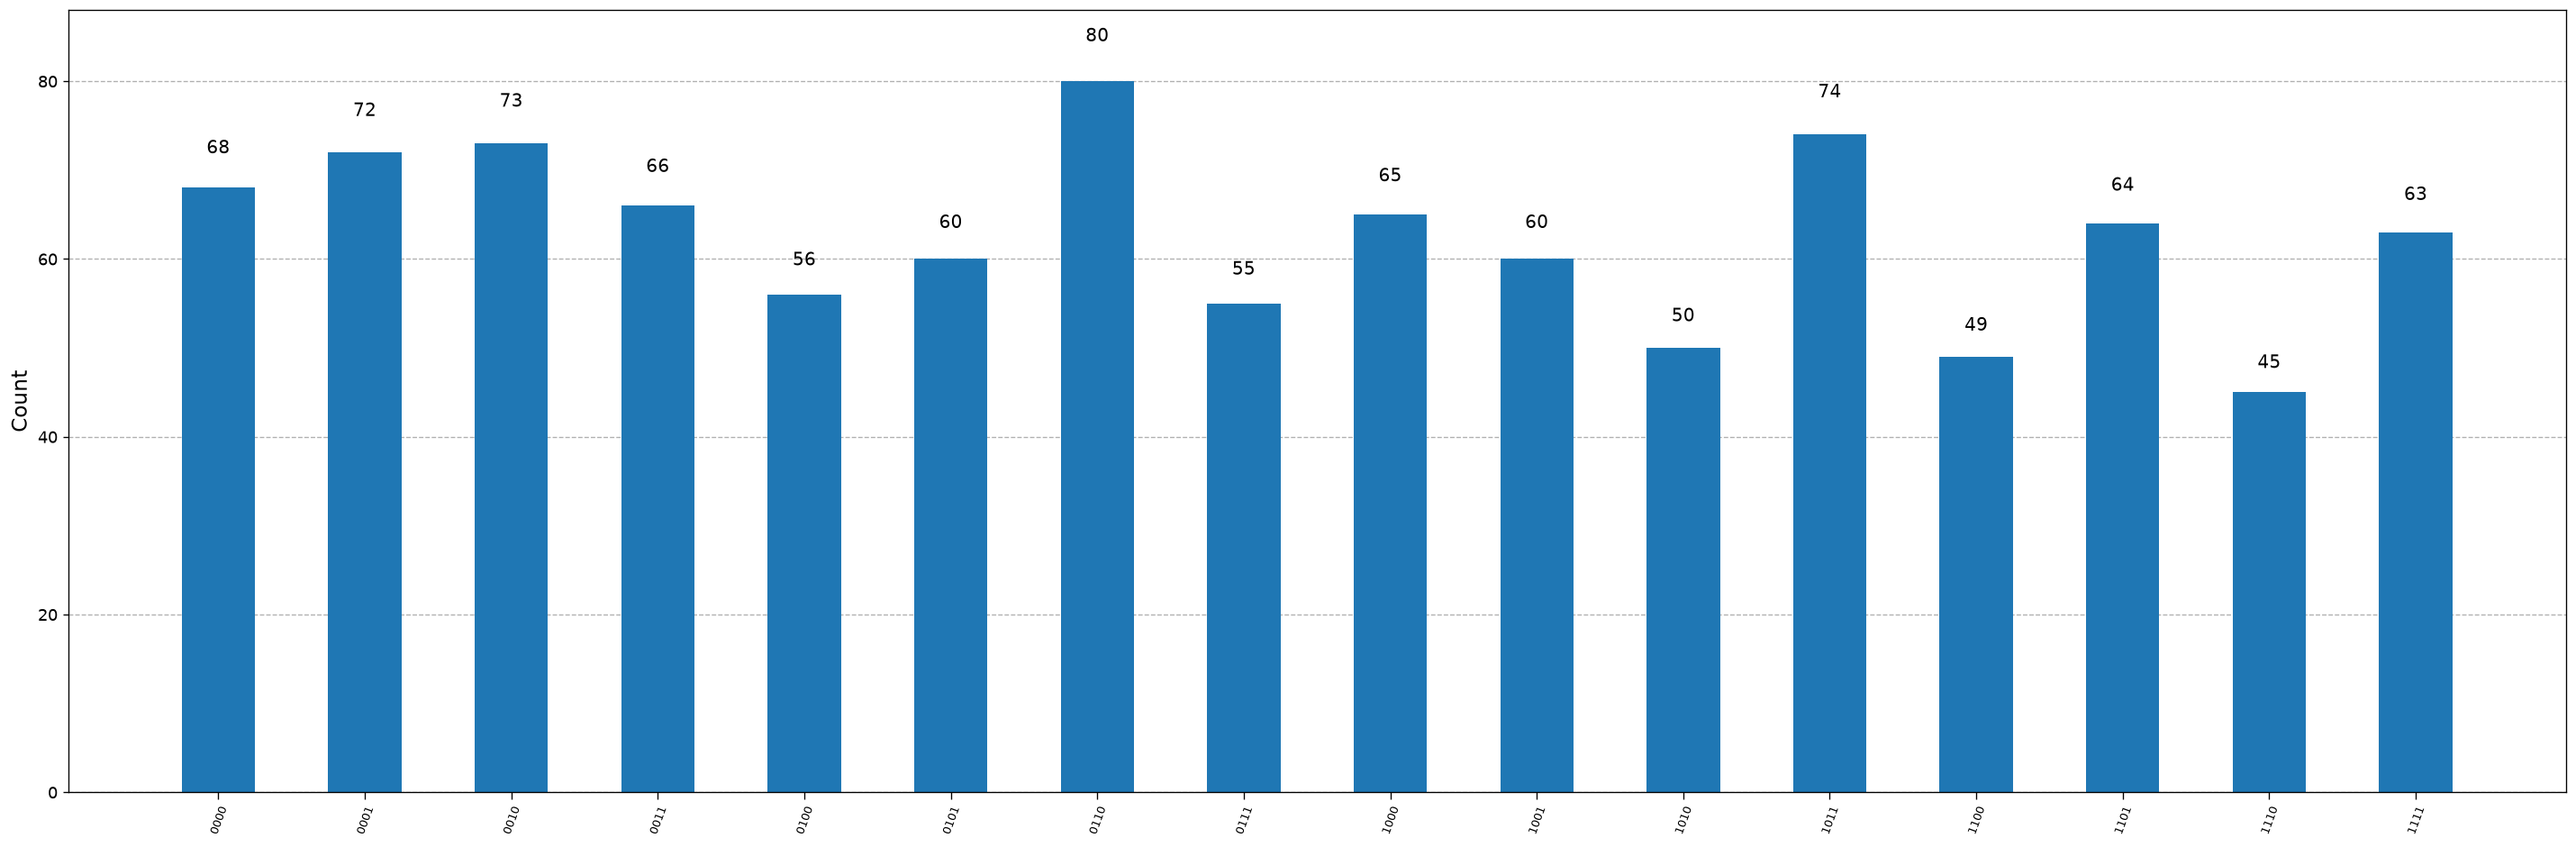

In [16]:
print ("4 qbits 20 iterations")
quantum = grover_quantum(4, 20)

Qcircuit = pm.run(quantum)

quantum.draw("mpl")

sampler = Sampler(mode=backend)

job = sampler.run([Qcircuit], shots=1000)

print("Job ID:", job.job_id())

result = job.result()

counts = result[0].data.meas.get_counts()

plot_histogram(counts)

5 qbits 15 iterations
Solutions:
|00011>
|10001>
|11100>
Job ID: dbdo4cgc77vs73eu9vsg


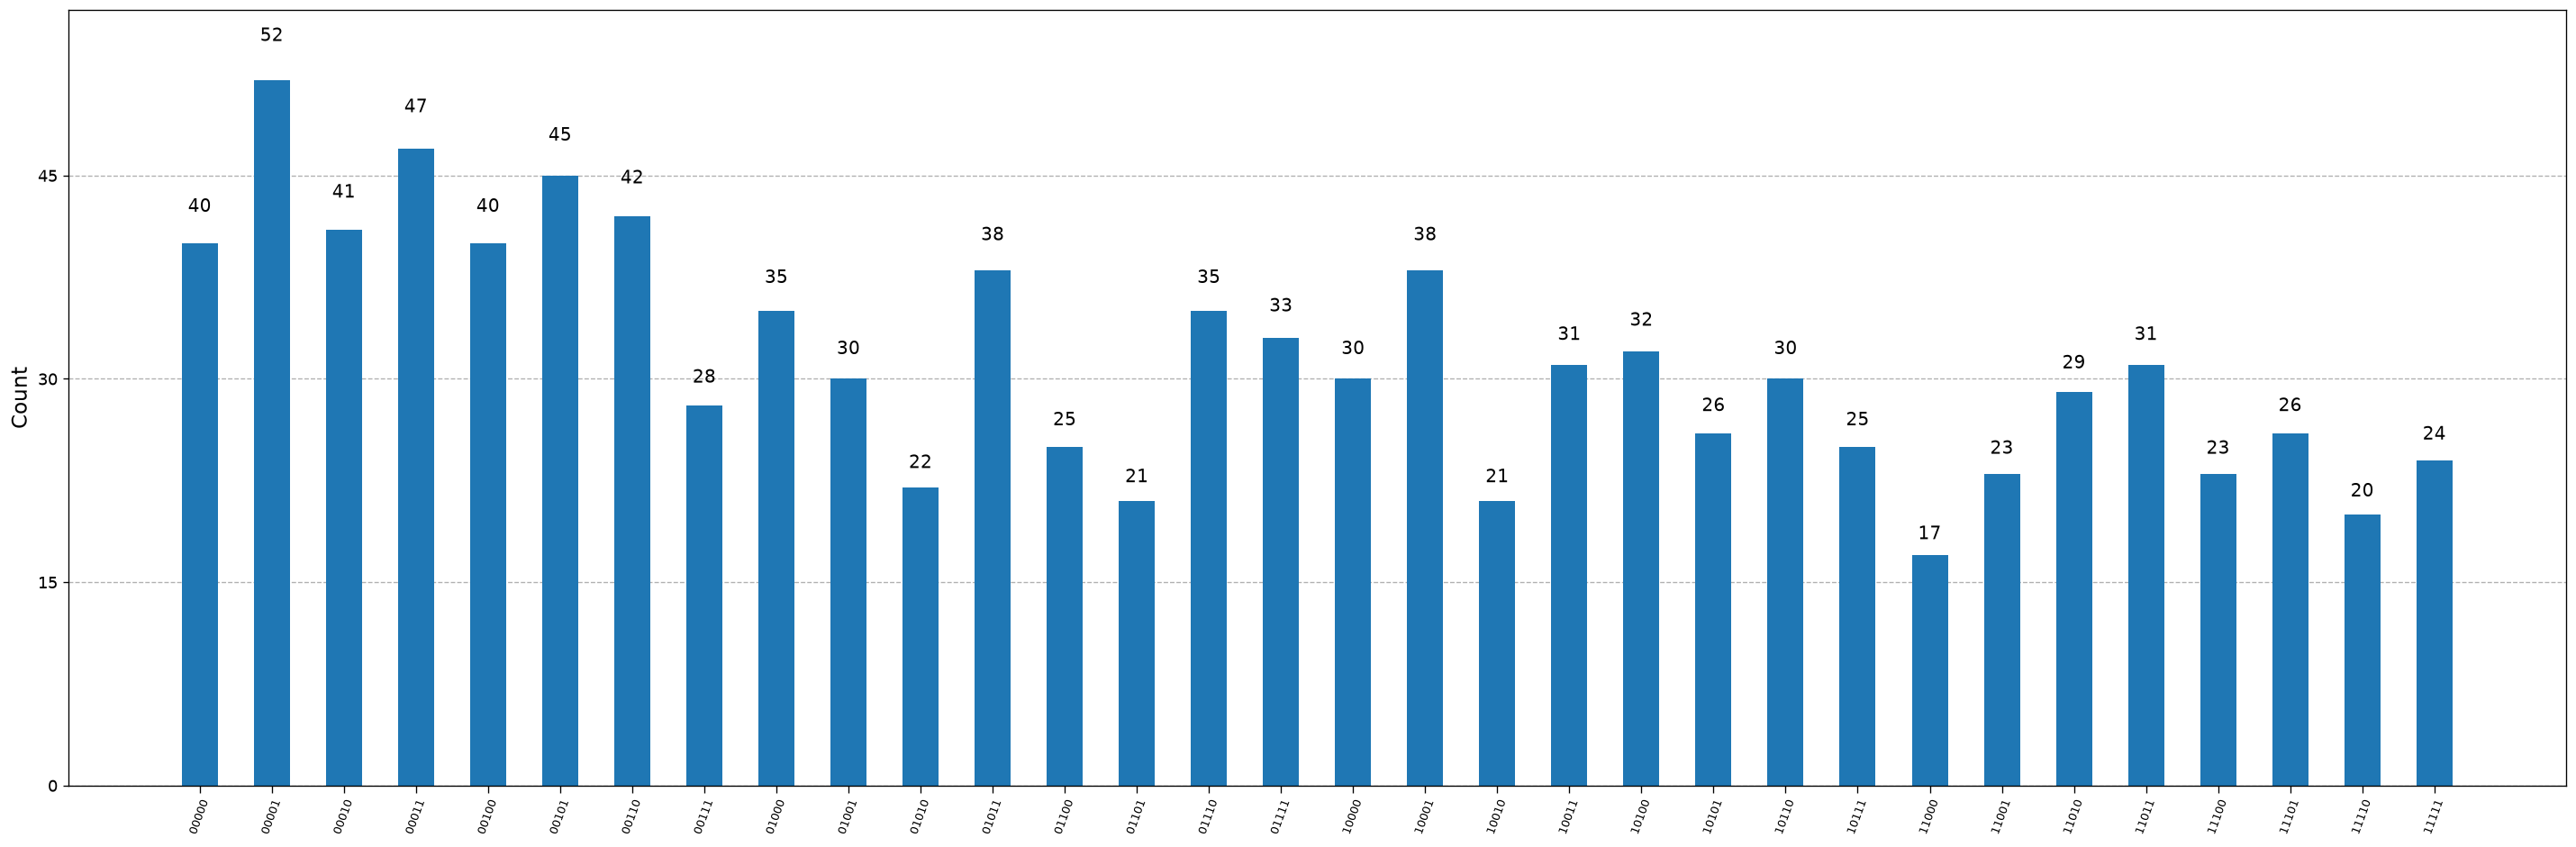

In [17]:
print ("5 qbits 15 iterations")
quantum = grover_quantum(5, 15)

Qcircuit = pm.run(quantum)

quantum.draw("mpl")

sampler = Sampler(mode=backend)

job = sampler.run([Qcircuit], shots=1000)

print("Job ID:", job.job_id())

result = job.result()

counts = result[0].data.meas.get_counts()

plot_histogram(counts)

6 qbits 5 iterations
Solutions:
|001011>
|101110>
|111100>
Job ID: dbdo631gv2cc73doqktg


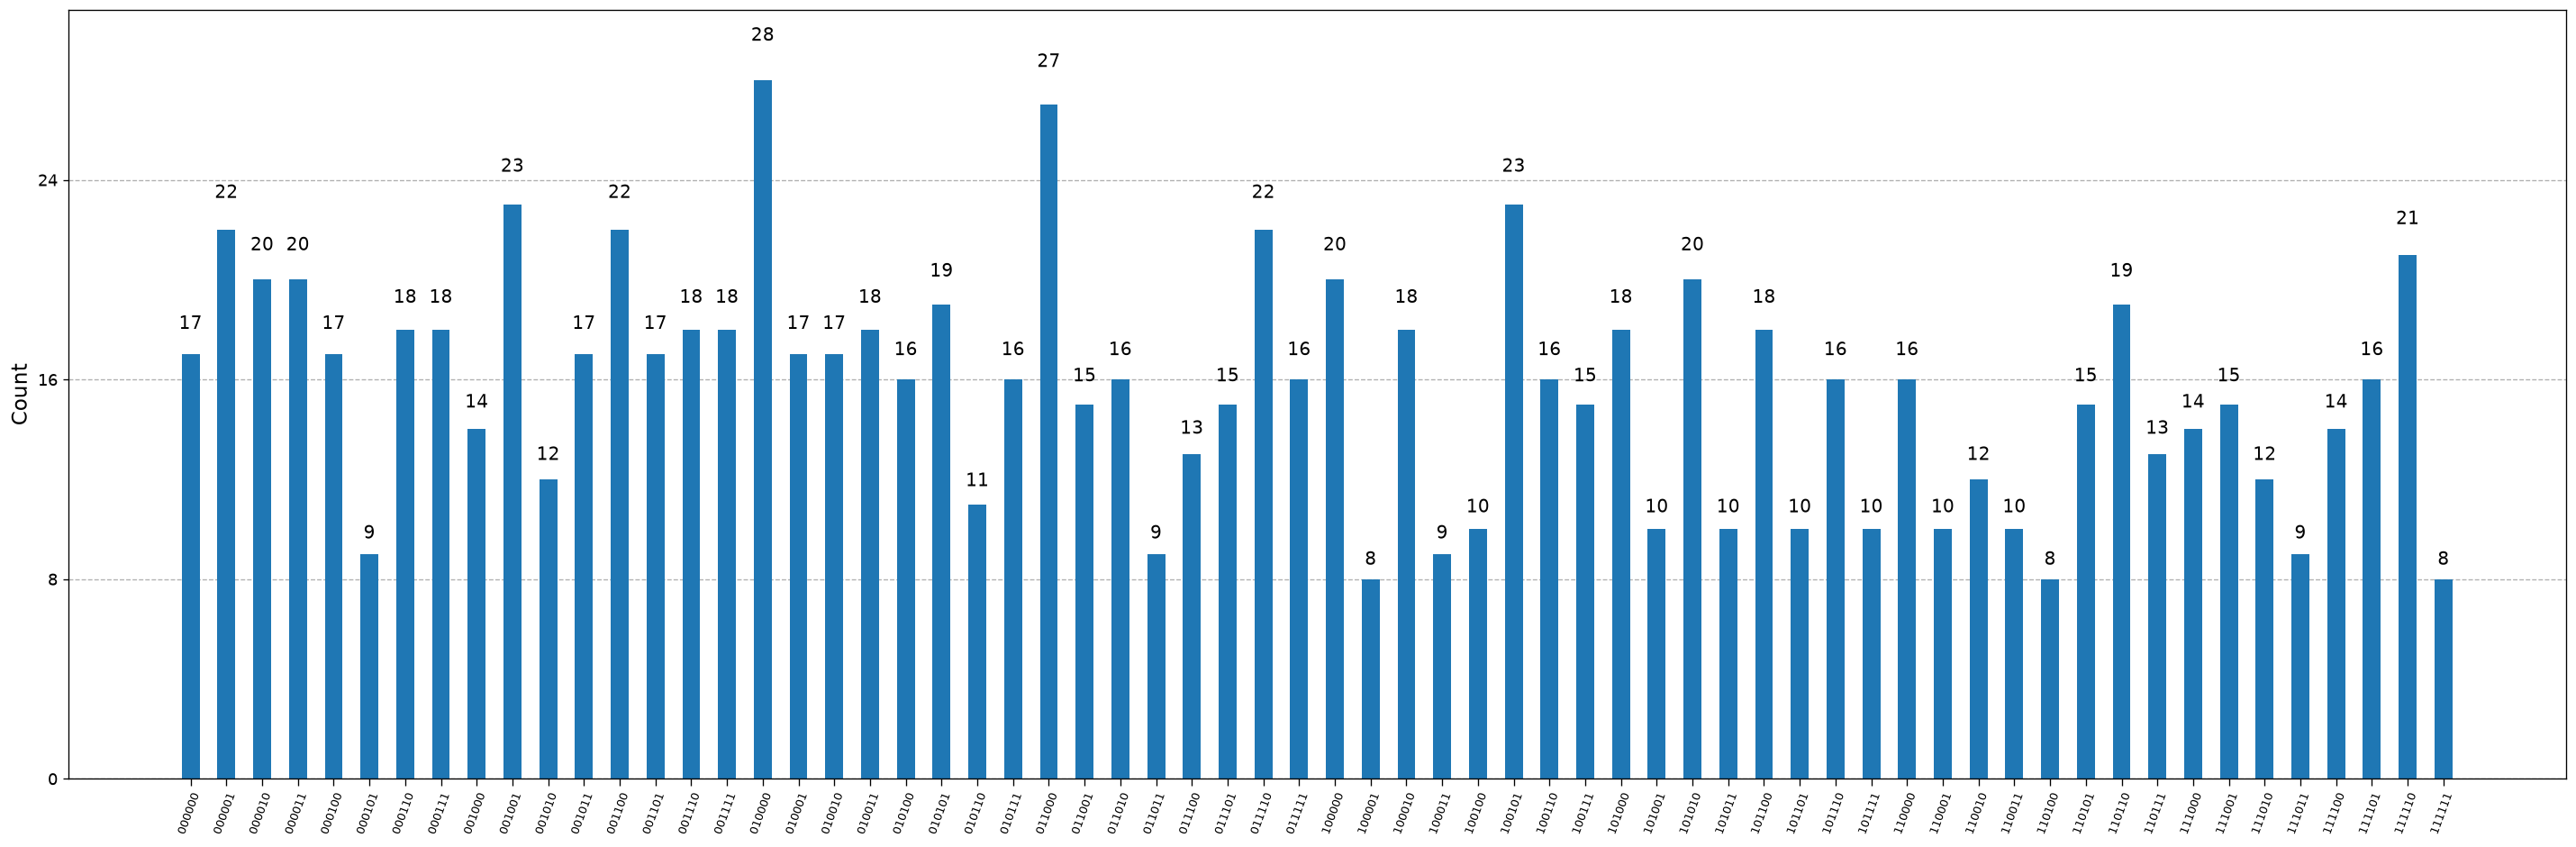

In [18]:
print ("6 qbits 5 iterations")
quantum = grover_quantum(6, 5)

Qcircuit = pm.run(quantum)

quantum.draw("mpl")

sampler = Sampler(mode=backend)

job = sampler.run([Qcircuit], shots=1000)

print("Job ID:", job.job_id())

result = job.result()

counts = result[0].data.meas.get_counts()

plot_histogram(counts)

<h1>Part 2</h1>